In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score

(100, 3)
Missing values:
 age       0
income    0
dtype: int64
         age    income
count  100.0     100.0
mean    41.9   95340.0
std     12.8   30218.1
min     21.0   45000.0
25%     31.0   70500.0
50%     42.0   97000.0
75%     52.2  119500.0
max     65.0  148000.0


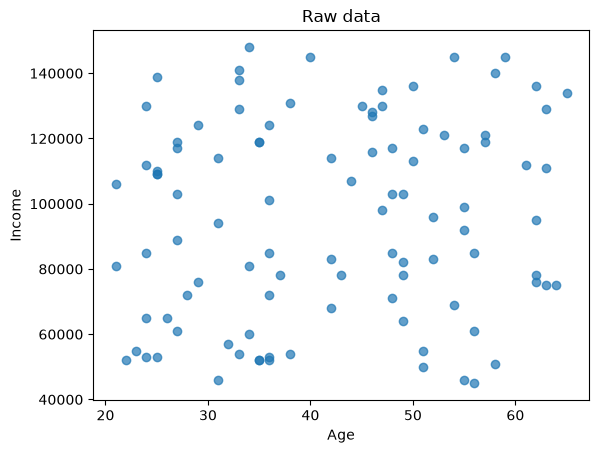

In [3]:
df = pd.read_csv(r"C:\Users\Lenovo\Downloads\people_income_data_large.csv")
features = ["age", "income"]
print(df.shape)
print("Missing values:\n", df[features].isna().sum())
print(df[features].describe().round(1))

plt.scatter(df["age"], df["income"], alpha=0.7)
plt.xlabel("Age")
plt.ylabel("Income")
plt.title("Raw data")
plt.show()

In [4]:
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(df[features])

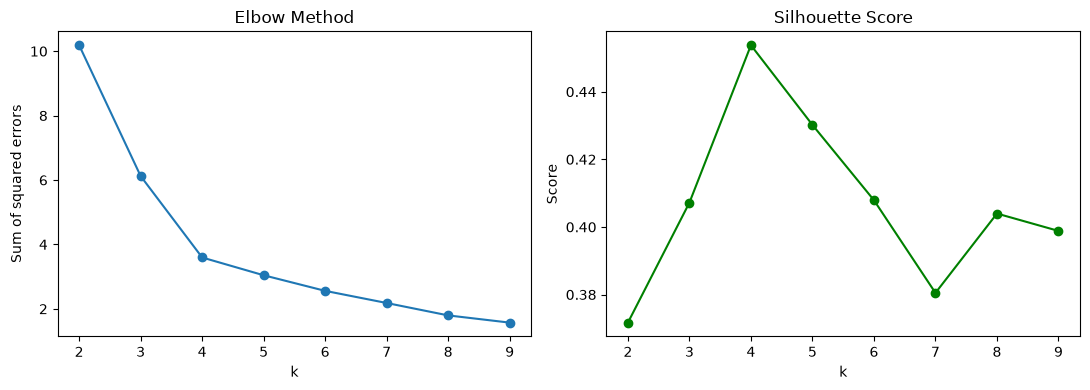

Silhouette by k: {2: 0.372, 3: 0.407, 4: 0.454, 5: 0.43, 6: 0.408, 7: 0.38, 8: 0.404, 9: 0.399}
Best k by silhouette: 4


In [5]:
k_range = range(2, 10)
sse, sil = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    sse.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(k_range, sse, "o-")
ax[0].set(title="Elbow Method", xlabel="k", ylabel="Sum of squared errors")
ax[1].plot(k_range, sil, "o-", color="green")
ax[1].set(title="Silhouette Score", xlabel="k", ylabel="Score")
plt.tight_layout()
plt.show()

best_k = list(k_range)[sil.index(max(sil))]
print("Silhouette by k:", {k: round(s, 3) for k, s in zip(k_range, sil)})
print("Best k by silhouette:", best_k)

In [6]:
K = 4  # set after reading the plots above (your own elbow points to 4)
km = KMeans(n_clusters=K, n_init=10, random_state=42)
df["cluster"] = km.fit_predict(X_scaled)
print(f"\nSilhouette (k={K}): {silhouette_score(X_scaled, df['cluster']):.3f}")


Silhouette (k=4): 0.454


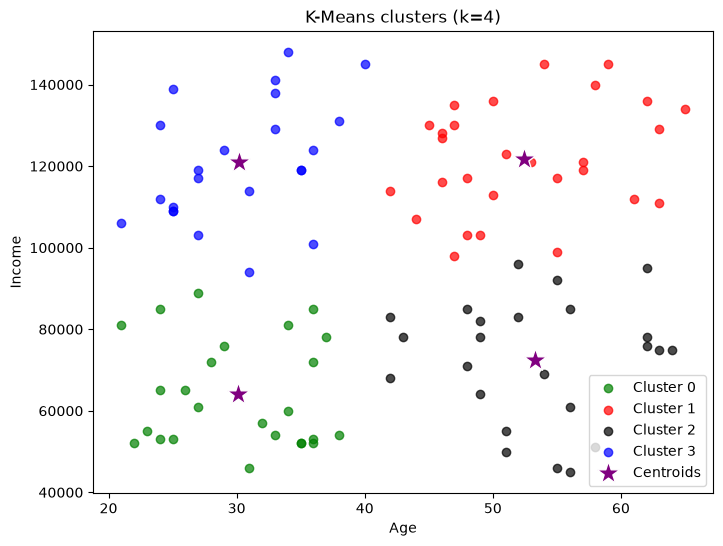

In [7]:
centers = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=features)
colors = ["green", "red", "black", "blue", "orange", "brown"]

plt.figure(figsize=(8, 6))
for c in range(K):
    part = df[df["cluster"] == c]
    plt.scatter(part["age"], part["income"], color=colors[c], alpha=0.7, label=f"Cluster {c}")
plt.scatter(centers["age"], centers["income"], color="purple", marker="*",
            s=300, edgecolor="white", label="Centroids")
plt.xlabel("Age")
plt.ylabel("Income")
plt.title(f"K-Means clusters (k={K})")
plt.legend()
plt.show()

In [8]:
profile = df.groupby("cluster").agg(
    people=("name", "count"),
    avg_age=("age", "mean"),
    avg_income=("income", "mean"),
    min_income=("income", "min"),
    max_income=("income", "max"),
).round(0)
print("\n--- Cluster profiles ---")
print(profile)


--- Cluster profiles ---
         people  avg_age  avg_income  min_income  max_income
cluster                                                     
0            25     30.0     64120.0       46000       89000
1            28     52.0    121750.0       98000      145000
2            24     53.0     72542.0       45000       96000
3            23     30.0    120913.0       94000      148000


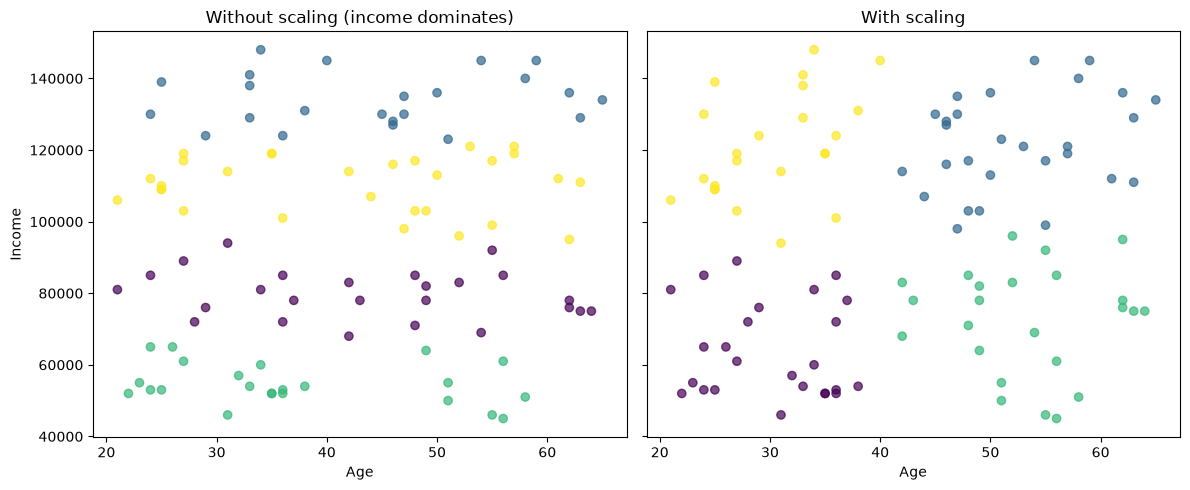

In [9]:
raw_labels = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(df[features])
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
ax[0].scatter(df["age"], df["income"], c=raw_labels, cmap="viridis", alpha=0.7)
ax[0].set(title="Without scaling (income dominates)", xlabel="Age", ylabel="Income")
ax[1].scatter(df["age"], df["income"], c=df["cluster"], cmap="viridis", alpha=0.7)
ax[1].set(title="With scaling", xlabel="Age")
plt.tight_layout()
plt.show()